# Decision Tree Regression

A regression tree cuts the x-axis into pieces and predicts the average of each piece. Here it predicts **mpg** from **horsepower**.

This notebook goes with the **Decision Tree Regression** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split → fit → compare depths → draw the staircase.

## 1. Load the data

Each row is a car from the late 1970s and early 1980s. We predict `mpg` from `horsepower`. A few cars have no horsepower listed, so we drop them first.

The data is the [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) data set from the UCI Machine Learning Repository (CC BY 4.0). See `datasets/README.md` for what we changed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor, export_text

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/mpg.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,usa
1,15.0,8,350.0,165.0,3693,11.5,70,usa
2,18.0,8,318.0,150.0,3436,11.0,70,usa
3,16.0,8,304.0,150.0,3433,12.0,70,usa
4,17.0,8,302.0,140.0,3449,10.5,70,usa


In [2]:
dataset = dataset.dropna(subset=['horsepower'])
X = dataset[['horsepower']].values
y = dataset['mpg'].values
print(X.shape, 'cars')

(392, 1) cars


## 2. Split into train and test

The model learns from the **training** cars (75%). We hold back the other 25% and only use them at the end. The test score shows how the model does on cars it has never seen. These are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

294 train, 98 test


## 3. Fit the tree

A tree asks "is horsepower below this number?" and keeps the question that makes the two sides most alike. `max_depth` limits how many questions in a row it may ask. Trees do not need feature scaling.

In [4]:
regressor = DecisionTreeRegressor(max_depth=3, random_state=0)
regressor.fit(X_train, y_train)
print(export_text(regressor, feature_names=['horsepower']))

|--- horsepower <= 96.50
|   |--- horsepower <= 70.50
|   |   |--- horsepower <= 47.00
|   |   |   |--- value: [26.00]
|   |   |--- horsepower >  47.00
|   |   |   |--- value: [34.24]
|   |--- horsepower >  70.50
|   |   |--- horsepower <= 84.50
|   |   |   |--- value: [27.90]
|   |   |--- horsepower >  84.50
|   |   |   |--- value: [24.39]
|--- horsepower >  96.50
|   |--- horsepower <= 139.50
|   |   |--- horsepower <= 118.00
|   |   |   |--- value: [20.47]
|   |   |--- horsepower >  118.00
|   |   |   |--- value: [18.18]
|   |--- horsepower >  139.50
|   |   |--- horsepower <= 166.00
|   |   |   |--- value: [14.93]
|   |   |--- horsepower >  166.00
|   |   |   |--- value: [13.04]



## 4. Check the result

**R²** says how much of the ups and downs in the data the model explains. 1 is perfect, 0 is no better than always guessing the average. The number that matters is the **test** R². The last line shows the typical miss in miles per gallon.

In [5]:
y_pred_train = regressor.predict(X_train)
y_pred_test = regressor.predict(X_test)
print('Train R²:', round(r2_score(y_train, y_pred_train), 3))
print('Test R²: ', round(r2_score(y_test, y_pred_test), 3))
print('Test error on average:', round(mean_absolute_error(y_test, y_pred_test), 2), 'mpg')

Train R²: 0.73
Test R²:  0.71
Test error on average: 3.08 mpg


## 5. Choose the depth

A deep tree gets close to one step per training car, so the train R² climbs while the test R² stalls or falls. That is **overfitting**.

In [6]:
for depth in [1, 2, 3, 4, 6, 10, None]:
    m = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_train, y_train)
    print(f'depth {str(depth):>4}: train R² {r2_score(y_train, m.predict(X_train)):.3f}   test R² {r2_score(y_test, m.predict(X_test)):.3f}')

depth    1: train R² 0.511   test R² 0.507
depth    2: train R² 0.698   test R² 0.666
depth    3: train R² 0.730   test R² 0.710
depth    4: train R² 0.768   test R² 0.693
depth    6: train R² 0.810   test R² 0.699
depth   10: train R² 0.834   test R² 0.608
depth None: train R² 0.835   test R² 0.610


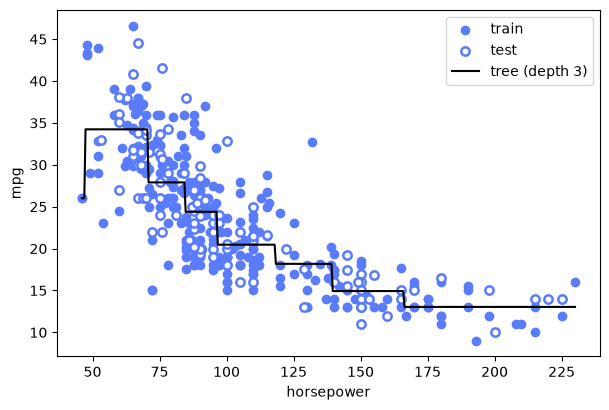

In [7]:
grid = np.linspace(X.min(), X.max(), 400).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_train, y_train, color='#5b7cfa', label='train')
plt.scatter(X_test, y_test, facecolors='white', edgecolors='#5b7cfa', linewidths=1.8, label='test')
plt.plot(grid, regressor.predict(grid), color='black', label='tree (depth 3)')
plt.xlabel('horsepower'); plt.ylabel('mpg'); plt.legend()
plt.show()

## Try this

1. Which depth gives the best test R²?
2. Print the tree at `max_depth=2` and follow it by hand for a car with 100 hp.
3. The curve is a staircase. Where would a smooth model, such as polynomial or SVR, do better?

## See it: the fit and the misses

**Left:** the fitted staircase through the cars. Filled dots are training cars and ringed dots are test cars. The test R² is in the title. **Right:** the residuals, which are the misses (actual mpg minus predicted mpg). **Notice how** the staircase gives every car in a step the same prediction, so the residuals come in vertical stripes, one per step.

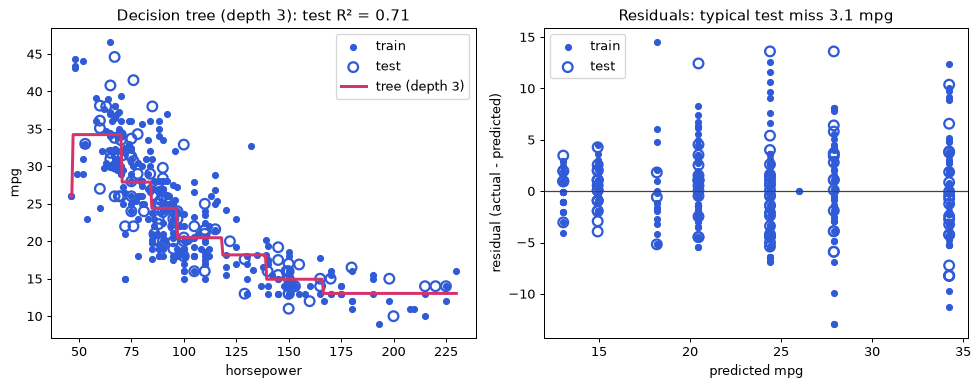

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

def model_predict(X_raw):
    return regressor.predict(X_raw)

xs = X[:, :1]
fit_x = np.linspace(xs.min(), xs.max(), 300).reshape(-1, 1)
yt, yte = np.ravel(y_train), np.ravel(y_test)
p_tr, p_te = model_predict(X_train), model_predict(X_test)
r2 = r2_score(yte, p_te)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.scatter(X_train[:, 0], yt, color=BLUE, s=22, label='train')
ax1.scatter(X_test[:, 0], yte, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax1.plot(fit_x[:, 0], model_predict(fit_x), color=PINK, linewidth=2.4, label='tree (depth 3)')
ax1.set_xlabel('horsepower'); ax1.set_ylabel('mpg')
ax1.set_title(f'Decision tree (depth 3): test R² = {r2:.2f}')
ax1.legend()

ax2.axhline(0, color='#444444', linewidth=1)
ax2.scatter(p_tr, yt - p_tr, color=BLUE, s=22, label='train')
ax2.scatter(p_te, yte - p_te, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax2.set_xlabel('predicted mpg'); ax2.set_ylabel('residual (actual - predicted)')
ax2.set_title(f'Residuals: typical test miss {np.abs(yte - p_te).mean():.1f} mpg')
ax2.legend()
fig.tight_layout()
plt.show()
